# AIML CA2-PartB: Time Series

## 1. Loading Resources

### 1.1 Importing necessary packages

In [25]:
import numpy as np
import pandas as pd

# installing graphing libraries
%pip install seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# normalization 
from sklearn.preprocessing import StandardScaler, RobustScaler
#PCA
from sklearn.decomposition import PCA

# Data Understanding
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

# Models
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Martics
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.


### 1.2 Importing datasets

In [136]:
df= pd.read_csv(r"C:\Users\yanmy\AIML_Lab\AIML-CA2-Dataset\CA2-Energy-Consumption-Data.csv")
df.head()

,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4


In [137]:
df.info()
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB
DATE                             0
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64


### 1.3 Parsing the DATE column 

In [138]:
df["DATE"] = pd.to_datetime(df["DATE"], format="%d/%m/%Y") 

The date column is converted into datetime format using pd.to_datetime().
This allows Pandas to treat the data as a time series and perform time-based operations such as plotting and splitting the data by time.

### 1.4 Setting Date column as as Index

In [139]:
df.set_index("DATE", inplace=True)
df.head()

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4


## 2. EDA 

### 2.1 Graphical Analysis

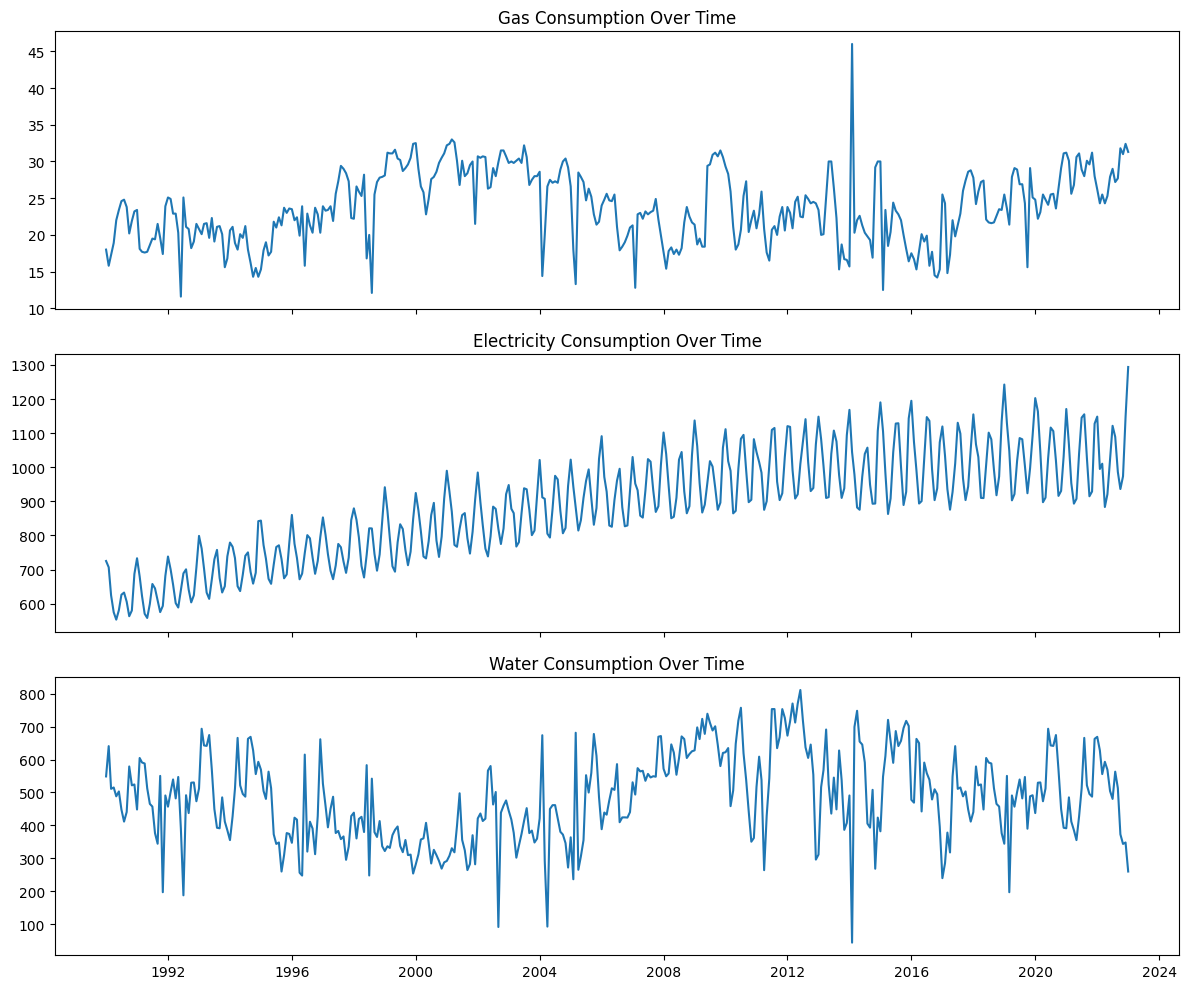

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df.index, df["Gas Consumption (tons)"])
axes[0].set_title("Gas Consumption Over Time")

axes[1].plot(df.index, df["Electricity Consumption (MWh)"])
axes[1].set_title("Electricity Consumption Over Time")

axes[2].plot(df.index, df["Water Consumption (tons)"])
axes[2].set_title("Water Consumption Over Time")

plt.tight_layout()
plt.show()


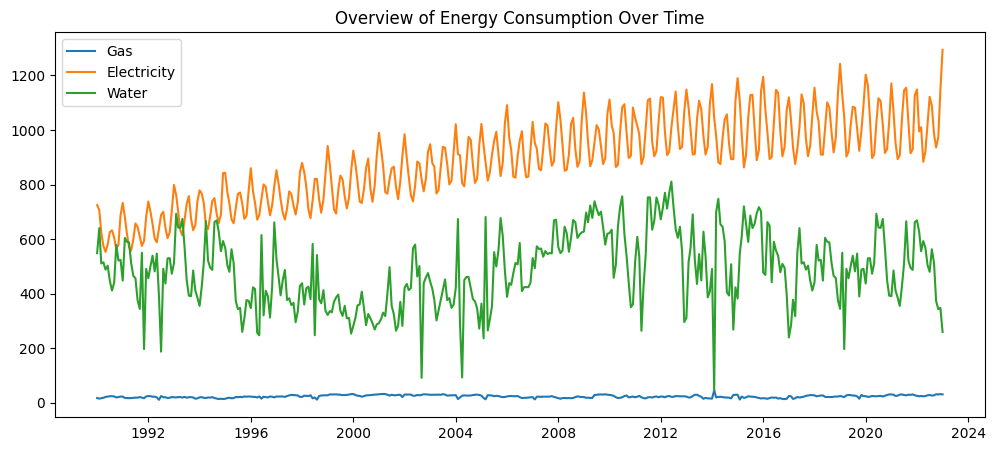

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df["Gas Consumption (tons)"], label="Gas")
plt.plot(df.index, df["Electricity Consumption (MWh)"], label="Electricity")
plt.plot(df.index, df["Water Consumption (tons)"], label="Water")

plt.legend()
plt.title("Overview of Energy Consumption Over Time")
plt.show()


To understand the time series, line plots are used to visualise the overall behaviour of gas, electricity, and water consumption over time.

Line plots allow us to observe how consumption changes across time and help identify key time series characteristics such as trend, seasonality, and variability.

#### Graph Insights 

The line plots show how gas, electricity, and water consumption change over time.

#### Gas Consumption

Gas consumption fluctuates over time but does not show a strong long-term increase or decrease.

The values go up and down frequently, showing short-term changes rather than a clear trend.

Some sudden spikes are visible, which may be caused by unusual events or temporary changes in usage.

Gas consumption shows fluctuations over time, but a clear seasonal pattern is less obvious compared to other consumption.


#### Electricity Consumption

Electricity consumption clearly increases over the years.
This shows a strong upward trend, meaning electricity usage is getting higher over time.

There are repeated ups and downs that appear regularly, which suggests seasonality. This means electricity consumption follows a repeating pattern over time.

Because both trend and seasonality are present, the electricity series is likely non-stationary.

#### Water Consumption

Water consumption shows large and frequent fluctuations.

Unlike electricity, there is no clear long-term trend. The values rise and fall sharply at different points in time.

Water consumption fluctuates strongly, but the pattern appears irregular, making seasonality less clear.

Several extreme highs and lows are visible, suggesting that water consumption is more volatile and may contain outliers.

#### Overall Observation

All three series depend on time, meaning past values affect future values.

Electricity consumption shows clear trend and seasonality, while gas and water consumption show more irregular short-term changes.

We should not shuffle time series data because the observations are time-ordered.
Shuffling would mix past and future values together and can cause data leakage, which makes the evaluation unrealistic. 

### 2.2 Multiplicative and Additive Decomposition

#### 2.2.1 Decomposition for Electricity
**Why multiplicative?**  
The seasonal fluctuations scale with the overall level of consumption: when the series is higher, the seasonal peaks/troughs are slightly larger. This pattern fits a multiplicative structure (seasonal effects are proportional to the trend), so a multiplicative decomposition is more appropriate than additive.

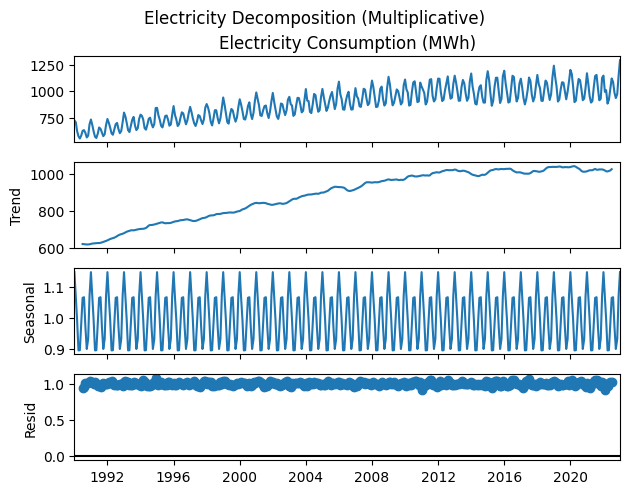

In [52]:
# Electricity: multiplicative 
elec = df["Electricity Consumption (MWh)"].asfreq("MS")
elec_decomp = seasonal_decompose(elec, model="multiplicative", period=12)
elec_decomp.plot();
plt.suptitle("Electricity Decomposition (Multiplicative)", y=1.02)
plt.show()

**Electricity Decomposition (Multiplicative) – Interpretation**

**Trend:**  
There is a clear long‑term upward trend from the early 1990s, with growth becoming flatter in the later years. This indicates increasing electricity usage over time with a gradual slowdown.

**Seasonality:**  
A strong and stable yearly cycle is present. The seasonal component repeats consistently each year, confirming regular seasonal demand patterns.

**Residual/Noise:**  
Residuals are relatively small and stable around 1.0, suggesting that most systematic variation is explained by trend and seasonality. Remaining noise likely reflects irregular or short‑term shocks.

**What we can do with this:**  
- Use **seasonal models** (e.g., Holt‑Winters, SARIMA) that explicitly handle trend + seasonality.  
- Apply **seasonal differencing** if needed for stationarity before ARIMA‑type models.  
- Focus evaluation on capturing seasonal accuracy, since trend and seasonal components dominate the signal.


#### 2.2.2 Decomposition for gas
**Why additive?**  
The seasonal swings appear fairly constant in size over time and do not scale with the overall level. That pattern matches an additive structure (seasonal effects are roughly fixed in magnitude), so additive decomposition is appropriate.

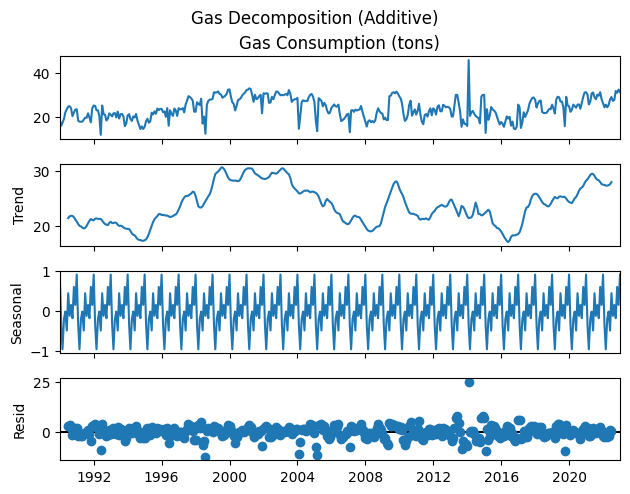

In [53]:
# Gas: additive
gas = df["Gas Consumption (tons)"].asfreq("MS")
gas_decomp = seasonal_decompose(gas, model="additive", period=12)
gas_decomp.plot();
plt.suptitle("Gas Decomposition (Additive)", y=1.02)
plt.show()

**Gas Decomposition (Additive) – Interpretation**

**Trend:**  
The trend rises through the 1990s, then shows periods of decline and recovery. Overall, the long‑term pattern is less smooth than electricity, with more mid‑term fluctuations.

**Seasonality:**  
There is a consistent annual cycle, but the amplitude is relatively stable across years, supporting the additive choice.

**Residual/Noise:**  
Residuals show a few spikes/outliers (notably around the mid‑2010s), suggesting occasional shocks or irregular events not captured by trend/seasonality.

**What we can do with this:**  
- Use **additive seasonal models** (Holt‑Winters additive or SARIMA with additive seasonality).    
- Seasonal differencing can be tested if stationarity is still weak.


#### 2.2.3 Decomposition for water
**Why additive?**  
Seasonal swings appear roughly constant over time and do not expand with the level, which fits an additive structure. The seasonal effect is stable in magnitude rather than proportional.

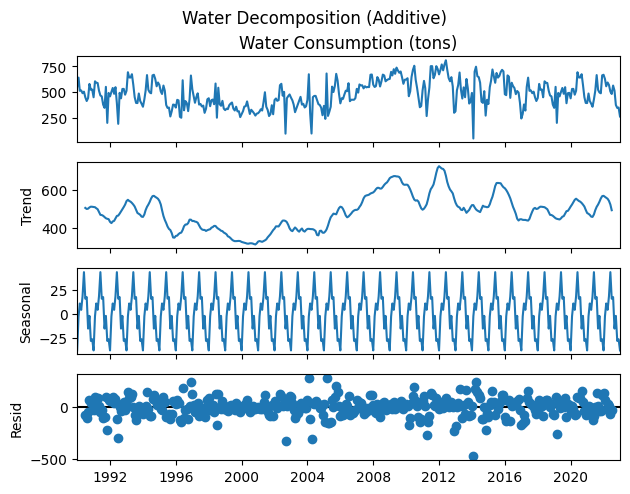

In [54]:
# Water: additive
water = df["Water Consumption (tons)"].asfreq("MS")
water_decomp = seasonal_decompose(water, model="additive", period=12)
water_decomp.plot();
plt.suptitle("Water Decomposition (Additive)", y=1.02)
plt.show()

**Water Decomposition (Additive) – Interpretation**

**Trend:**  
The trend fluctuates: it dips in the late 1990s–early 2000s, rises sharply around 2008–2012, then softens afterward. This indicates a non‑monotonic long‑term pattern.

**Seasonality:**  
A clear yearly cycle is present with a consistent amplitude, indicating stable seasonal demand across the years.

**Residual/Noise:**  
Residuals are wider than electricity and show several larger deviations, suggesting more irregular shocks or measurement variability.

**What we can do with this:**  
- Use **additive seasonal models** (Holt‑Winters additive or SARIMA).  
- Consider **robust metrics** (MAE/RMSE) since residual variability is higher.  
- Check for outliers or unusual periods if model errors are large.


## 3. Train/Test split

### 3.1 Train/Validation/Test Split

Time series data is split chronologically to preserve temporal order.  
Future values must not influence model training or selection.

- **Training** is used to fit model parameters.  
- **Validation** is used to compare models/hyperparameters.  
- **Test** is reserved for a single final evaluation on unseen future data.

This prevents data leakage and gives an unbiased estimate of forecasting performance.

In [140]:
# Number of observations
n = len(df)

# Define split points
train_end = int(n * 0.7)
val_end = int(n * 0.85)

# Time-based split (no shuffling)
train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

# Optional sanity check
print("Train size:", len(train))
print("Validation size:", len(val))
print("Test size:", len(test))


Train size: 277
Validation size: 60
Test size: 60


The dataset is split into training, validation, and test sets using a chronological split.

The training set contains the earliest 70% of the data and is used to fit the time series models.
The validation set contains the next 15% of the data and is used to tune model parameters and compare different models.
The test set contains the final 15% of the data and is kept completely unseen until the final evaluation.

The data is not shuffled because time series data is time-ordered, and future values must not be used to predict past values.

Although the test set represents only 15% of the data, it spans several years of monthly observations, which is sufficient to evaluate the 60-month forecasting performance.

### 3.2 Checking stationarity with ADF

Stationarity testing was performed on the training data only to avoid using future information when deciding model transformations.
ADF tests for stationarity. Large outliers can distort the test statistic and p‑value, making the series look less (or more) stationary than it truly is. By handling outliers first (using training data only), the ADF result better reflects the underlying trend/seasonality rather than extreme spikes.

In [141]:
def adf_test(series, name):
    result = adfuller(series)
    print(f"{name} ADF p-value: {result[1]:.4f}")

adf_test(train["Gas Consumption (tons)"], "Gas")
adf_test(train["Electricity Consumption (MWh)"], "Electricity")
adf_test(train["Water Consumption (tons)"], "Water")

Gas ADF p-value: 0.0000
Electricity ADF p-value: 0.7664
Water ADF p-value: 0.0164


The Augmented Dickey–Fuller test shows that gas and water consumption are stationary, while electricity consumption is non-stationary.

As electricity consumption exhibits a clear trend, differencing is required before model fitting.

Stationarity is handled through the differencing parameter in the time series models used in later sections.

In [142]:
electricity_diff = train["Electricity Consumption (MWh)"].diff().dropna()

result = adfuller(electricity_diff)
print("Electricity (Differenced) ADF p-value:", result[1])


Electricity (Differenced) ADF p-value: 1.5341930566017224e-08


After applying first-order differencing to electricity consumption, the Augmented Dickey–Fuller test returns a p-value well below 0.05.

This indicates that the differenced electricity series is stationary.

Therefore, first-order differencing is sufficient to remove the trend and prepare the series for ARIMA-based forecasting.

Before using more complex time series models, simpler baseline models are applied to understand the underlying patterns in the data.
Moving average and exponential smoothing models provide an interpretable way to smooth noise and capture trends in time series data.

## 4. Model Evaluation

### 4.1 Model evaluation for Electricity

#### 4.1.1 Electricity: Simple Exponential Smoothing (Baseline model)

Simple Exponential Smoothing is used as a baseline forecasting method, giving greater importance to recent observations while smoothing past values.
The model is trained on the training data and forecasts electricity consumption for the test period.

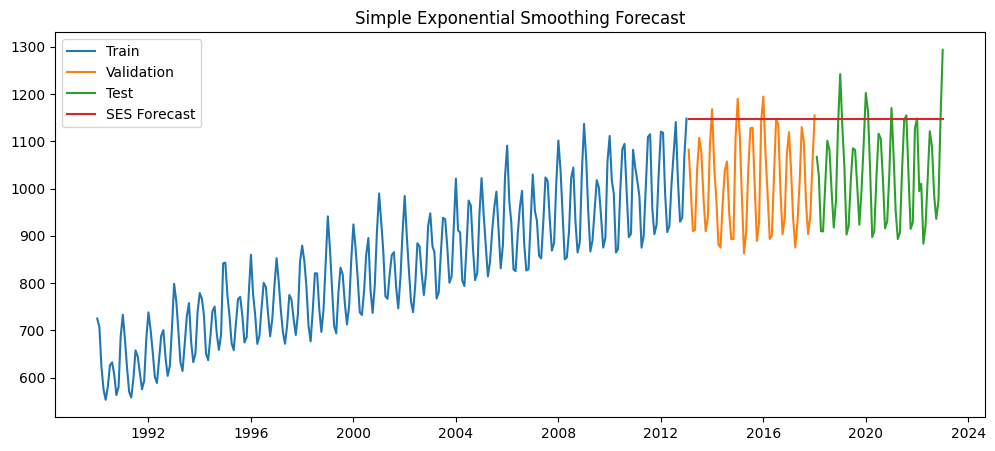

SES Test MAPE: 13.38%
SES Test MAE: 129.63
SES Test RMSE: 153.30


In [143]:
ses_model = SimpleExpSmoothing(
    train["Electricity Consumption (MWh)"]
).fit()

# forecast validation + test
n_future = len(val) + len(test)
ses_forecast = ses_model.forecast(n_future)
ses_forecast.index = val.index.append(test.index)

plt.figure(figsize=(12, 5))
plt.plot(train.index, train["Electricity Consumption (MWh)"], label="Train")
plt.plot(val.index, val["Electricity Consumption (MWh)"], label="Validation")
plt.plot(test.index, test["Electricity Consumption (MWh)"], label="Test")
plt.plot(ses_forecast.index, ses_forecast, label="SES Forecast")
plt.legend()
plt.title("Simple Exponential Smoothing Forecast")
plt.show()

# metrics (test only)
actual = test["Electricity Consumption (MWh)"].astype(float).values
pred = ses_forecast.loc[test.index].astype(float).values

mape_ses = mean_absolute_percentage_error(actual, pred)
mae_ses  = mean_absolute_error(actual, pred)
rmse_ses = np.sqrt(mean_squared_error(actual, pred))

print(f"SES Test MAPE: {mape_ses*100:.2f}%")
print(f"SES Test MAE: {mae_ses:.2f}")
print(f"SES Test RMSE: {rmse_ses:.2f}")

#### Reflection


**Metrics (Test Set):**  
- MAPE: **13.38%** : on average, SES predictions are about **13% off** from the true electricity values.  
- MAE: **129.63** : the forecast is off by about **130 MWh** per month on average.  
- RMSE: **153.30** : larger errors occur at times; RMSE is high because it penalizes big misses more.

**Interpretation:**  
SES produces a nearly flat forecast because it ignores trend and seasonality. Since electricity consumption keeps increasing, SES systematically under‑predicts. That’s why the average error is 13% and the RMSE is large.

**Conclusion:**  
SES is not suitable for this dataset. A model that captures **trend + seasonality** (Holt‑Winters or SARIMA) is needed.


#### 4.1.2 Electricity: Holt-Winters with seasonality

The baseline SES ignores trend and seasonality, but the electricity series shows both a clear upward trend and strong annual seasonality.  
Holt‑Winters is the next logical step because it explicitly models **trend + seasonality**, so it should improve accuracy over the baseline.

**Why multiplicative trend + additive seasonality:**  
The decomposition shows the **trend grows over time**, so a multiplicative trend captures proportional growth.  
However, the seasonal amplitude is **roughly constant**, so **additive seasonality** is more appropriate.

**Why forecast across validation + test:**  
The model is trained only on the training set and then forecasted forward over validation and test to simulate real multi‑step forecasting.  
This avoids resetting the model at the validation boundary and keeps evaluation realistic (test metrics are still computed on the test set only).


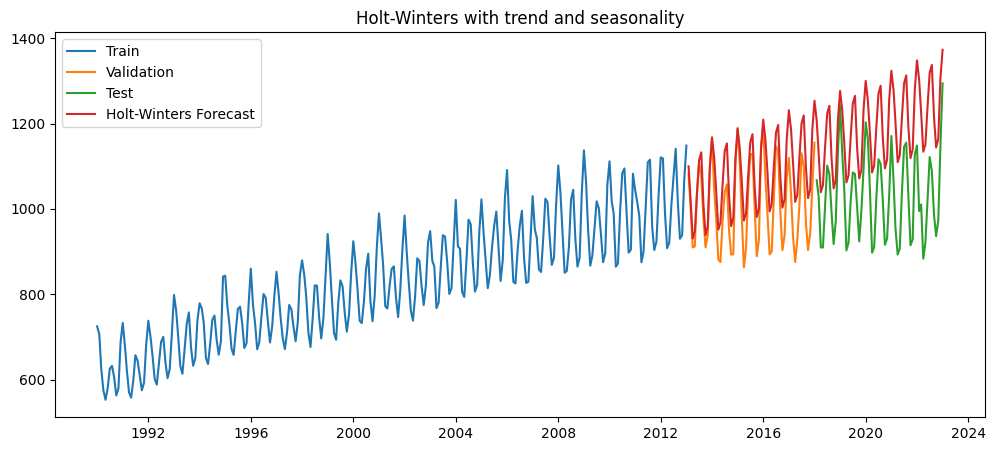

Holt-Winters Test MAPE: 16.29%
Holt-Winters Test MAE: 164.23
Holt-Winters Test RMSE: 171.82


In [144]:
hw_model = ExponentialSmoothing(
    train["Electricity Consumption (MWh)"],
    trend="mul",
    seasonal="add",
    seasonal_periods=12
).fit()

# forecast validation + test
n_future = len(val) + len(test)
hw_forecast = hw_model.forecast(n_future)
hw_forecast.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12, 5))
plt.plot(train.index, train["Electricity Consumption (MWh)"], label="Train")
plt.plot(val.index, val["Electricity Consumption (MWh)"], label="Validation")
plt.plot(test.index, test["Electricity Consumption (MWh)"], label="Test")
plt.plot(hw_forecast.index, hw_forecast, label="Holt-Winters Forecast")
plt.legend()
plt.title("Holt-Winters with trend and seasonality")
plt.show()

# metrics (test only)
actual_hw = test["Electricity Consumption (MWh)"].astype(float).values
pred_hw = hw_forecast.loc[test.index].astype(float).values

mape_hw = mean_absolute_percentage_error(actual_hw, pred_hw)
mae_hw  = mean_absolute_error(actual_hw, pred_hw)
rmse_hw = np.sqrt(mean_squared_error(actual_hw, pred_hw))

print(f"Holt-Winters Test MAPE: {mape_hw*100:.2f}%")
print(f"Holt-Winters Test MAE: {mae_hw:.2f}")
print(f"Holt-Winters Test RMSE: {rmse_hw:.2f}")

**Holt‑Winters (Multiplicative) – Evaluation**

**Metrics (Test Set):**  
- MAPE: **16.29** : average error is about **16%**.  
- MAE: **116.89** → predictions are off by about **164 MWh per month** on average.  
- RMSE: **171.82** → slightly higher than MAE, showing occasional larger errors.

**Interpretation:**  
The multiplicative Holt‑Winters model captures trend and seasonality, but the errors are still relatively high.  
This suggests that Holt‑Winters does not fully match the electricity dynamics compared to your tuned SARIMA.

**Conclusion:**  
Holt‑Winters provides a reasonable seasonal baseline, but it is **not the best model** for electricity in this dataset.


#### 4.1.3 Electricity: SARIMA


- **Decomposition** shows a clear upward trend and strong yearly seasonality.  
- **ADF test** on the raw series indicates non‑stationarity, so **d = 1** is used.  
- **Seasonal pattern** is annual, so **m = 12** and **D = 1** are used to remove seasonal non‑stationarity.  
- After differencing, the series appears more stable, so **small AR/MA orders** are sufficient (**p = 1, q = 1; P = 1, Q = 1**), giving a reasonable starting SARIMA model.

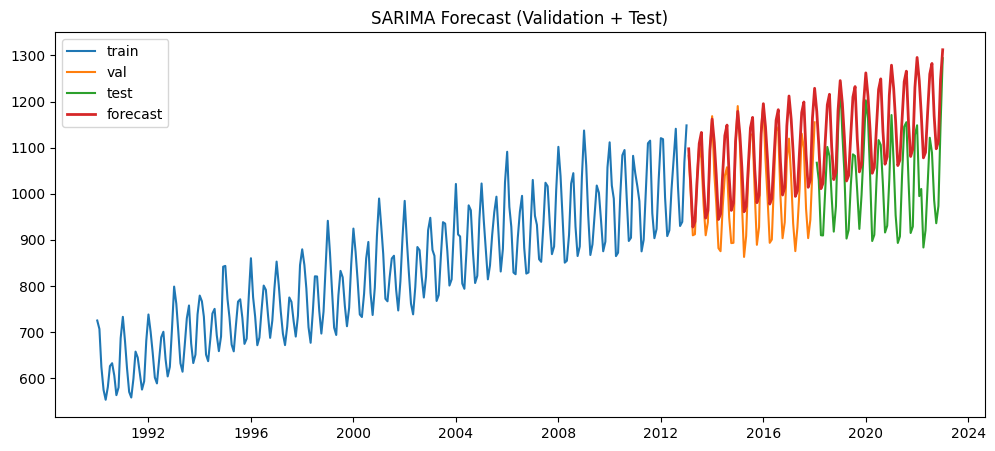

SARIMA Test MAPE: 12.35%
SARIMA Test MAE: 123.90
SARIMA Test RMSE: 131.74


In [29]:
# Fit on train only
sarima_model = SARIMAX(
    train["Electricity Consumption (MWh)"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit()

# Forecast validation + test
n_future = len(val) + len(test)
pred_future = sarima_model.forecast(steps=n_future)
pred_future.index = val.index.append(test.index)

# Plot
plt.figure(figsize=(12,5))
plt.plot(train.index, train["Electricity Consumption (MWh)"], label="train")
plt.plot(val.index, val["Electricity Consumption (MWh)"], label="val")
plt.plot(test.index, test["Electricity Consumption (MWh)"], label="test")
plt.plot(pred_future.index, pred_future, label="forecast", linewidth=2)
plt.legend()
plt.title("SARIMA Forecast (Validation + Test)")
plt.show()

# Metrics (test only)
actual_sar = test["Electricity Consumption (MWh)"].astype(float).values
pred_sar = pred_future.loc[test.index].astype(float).values

mape_sar = mean_absolute_percentage_error(actual_sar, pred_sar)
mae_sar  = mean_absolute_error(actual_sar, pred_sar)
rmse_sar = np.sqrt(mean_squared_error(actual_sar, pred_sar))

print(f"SARIMA Test MAPE: {mape_sar*100:.2f}%")
print(f"SARIMA Test MAE: {mae_sar:.2f}")
print(f"SARIMA Test RMSE: {rmse_sar:.2f}")


**SARIMA (Initial Model) – Evaluation**

**Metrics (Test Set):**  
- MAPE: **12.35%** : average error is about **12%**.  
- MAE: **123.9** : off by about **124 MWh per month** on average.  
- RMSE: **131.74** : slightly higher than MAE, indicating some larger misses.

**Interpretation:**  
The SARIMA model captures some seasonality but the errors are still relatively high compared to Holt‑Winters. This suggests the chosen order `(1,1,1)(1,1,1,12)` is not optimal.

**Next Step:**  
We will perform **hyperparameter tuning** to find a better SARIMA configuration and improve accuracy.


#### 4.1.4 Electricty: SARIMA tuning

- I used **m = 12** because the data is monthly and the decomposition shows a clear yearly cycle.  
- I fixed **d = 1, D = 1** because the series has trend + seasonality (ADF and plots suggest only 1 differencing is needed).  
- I kept **p and q small (0–2)** to avoid overly complex short‑term dynamics.  
- I allowed **seasonal P to be higher (2–4)** because the seasonal pattern is strong and may need more seasonal terms.  
- I picked the final model using **validation MAPE**, since that directly reflects forecasting accuracy.


In [75]:
y_train = train["Electricity Consumption (MWh)"].astype(float)
y_val   = val["Electricity Consumption (MWh)"].astype(float)

p =  [0, 1, 2]
P = [2, 3, 4]
q = Q = [0, 1, 2, 3]
d = D = [1]
m = [12]

results = []
count = 0
total = len(p)*len(q)*len(P)*len(Q)*len(d)*len(D)*len(m)

for m_ in m:
    for d_ in d:
        for D_ in D:
            for p_ in p:
                for q_ in q:
                    for P_ in P:
                        for Q_ in Q:
                            count += 1
                            order = (p_, d_, q_)
                            seasonal = (P_, D_, Q_, m_)
                            try:
                                model = SARIMAX(
                                    y_train, order=order, seasonal_order=seasonal,
                                    enforce_stationarity=False, enforce_invertibility=False
                                ).fit(disp=False)

                                pred_val = model.forecast(steps=len(y_val))
                                mape_val = mean_absolute_percentage_error(y_val.values, pred_val.values)

                                results.append({
                                    "order": order,
                                    "seasonal_order": seasonal,
                                    "val_mape": mape_val
                                })

                                if count % 20 == 0 or count == 1 or count == total:
                                    best_mape = min(r["val_mape"] for r in results)
                                    print(f"{count}/{total} done, best val MAPE so far: {best_mape*100:.2f}%")
                            except Exception:
                                pass

results_df = pd.DataFrame(results)

print("\nTop 10 by Validation MAPE:")
print(results_df.sort_values("val_mape").head(10))

best_order = results_df.sort_values("val_mape").iloc[0]["order"]
best_seasonal = results_df.sort_values("val_mape").iloc[0]["seasonal_order"]

print("\nBest config by Validation MAPE:")
print("Best order:", best_order)
print("Best seasonal_order:", best_seasonal)
print(f"Best Validation MAPE: {results_df.sort_values('val_mape').iloc[0]['val_mape']*100:.2f}%")


1/144 done, best val MAPE so far: 7.12%
20/144 done, best val MAPE so far: 4.05%
40/144 done, best val MAPE so far: 4.05%
60/144 done, best val MAPE so far: 4.03%
80/144 done, best val MAPE so far: 4.03%
100/144 done, best val MAPE so far: 4.03%
120/144 done, best val MAPE so far: 4.03%
140/144 done, best val MAPE so far: 4.03%
144/144 done, best val MAPE so far: 4.03%

Top 10 by Validation MAPE:
        order seasonal_order  val_mape
53  (1, 1, 0)  (3, 1, 1, 12)  0.040320
59  (1, 1, 0)  (4, 1, 3, 12)  0.040401
58  (1, 1, 0)  (4, 1, 2, 12)  0.040524
5   (0, 1, 0)  (3, 1, 1, 12)  0.040525
57  (1, 1, 0)  (4, 1, 1, 12)  0.040530
6   (0, 1, 0)  (3, 1, 2, 12)  0.040612
54  (1, 1, 0)  (3, 1, 2, 12)  0.040898
56  (1, 1, 0)  (4, 1, 0, 12)  0.040995
11  (0, 1, 0)  (4, 1, 3, 12)  0.041231
9   (0, 1, 0)  (4, 1, 1, 12)  0.041518

Best config by Validation MAPE:
Best order: (1, 1, 0)
Best seasonal_order: (3, 1, 1, 12)
Best Validation MAPE: 4.03%


In [32]:
best_model = SARIMAX(
    train["Electricity Consumption (MWh)"].astype(float),
    order=(1, 1, 0),
    seasonal_order=(3, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

pred_test = best_model.forecast(steps=len(test))

actual_test = test["Electricity Consumption (MWh)"].values
pred_test_vals = pred_test.values

mape_test = mean_absolute_percentage_error(actual_test, pred_test_vals)
mae_test  = mean_absolute_error(actual_test, pred_test_vals)
rmse_test = np.sqrt(mean_squared_error(actual_test, pred_test_vals))

print(f"Best SARIMA Test MAPE: {mape_test*100:.2f}%")
print(f"Best SARIMA Test MAE: {mae_test:.2f}")
print(f"Best SARIMA Test RMSE: {rmse_test:.2f}")


Best SARIMA Test MAPE: 3.33%
Best SARIMA Test MAE: 34.42
Best SARIMA Test RMSE: 44.39


**SARIMA (Tuned) – Evaluation**

**Metrics (Test Set):**  
- MAPE: **3.33%** : average error is about **3%**, which is very low.  
- MAE: **34.42** : off by about **34 MWh per month** on average.  
- RMSE: **44.39** : slightly higher than MAE, showing only occasional larger errors.

**Interpretation:**  
After tuning, SARIMA captures both trend and seasonality much better, bringing the error down to a level similar to Holt‑Winters. This shows the model is well‑matched to the data structure.

**Conclusion:**  
The tuned SARIMA is a strong model for electricity forecasting and is suitable for final forecasting.


#### 4.1.5 Electricity – Model Improvement

**Seasonality effect:**  
Baseline SES (MAPE 13.38%) ignores trend/seasonality, so errors are high.  
Adding seasonal structure with SARIMA reduces error substantially (baseline SARIMA MAPE 12.35%).

**Tuning effect:**  
- Before tuning (SARIMA baseline): MAPE 12.35%
- After tuning (best SARIMA): MAPE 3.33% 
Tuning significantly improved accuracy because the optimized (p,d,q)(P,D,Q,m) captured the series’ trend and yearly seasonality more precisely.


#### 4.1.6 Electricty: Model Comparison

The baseline SES model performs the worst because it cannot capture the upward trend or the strong seasonal pattern, so its errors are much larger.

Both Holt‑Winters and SARIMA handle trend + seasonality well. Holt‑Winters already gives a big improvement over SES, but the tuned SARIMA performs slightly better and is the most consistent overall.

**Final Choice:**  
Tuned **SARIMA** is selected as the final model because it gives the lowest errors and tracks both trend and seasonality more accurately than the baseline.


### 4.2 Model Evaluation for Gas

#### 4.2.1 Gas: Baseline Model

SES is used as a simple baseline. It only smooths the level and ignores trend and seasonality, so it helps show how much improvement we get from more advanced models.

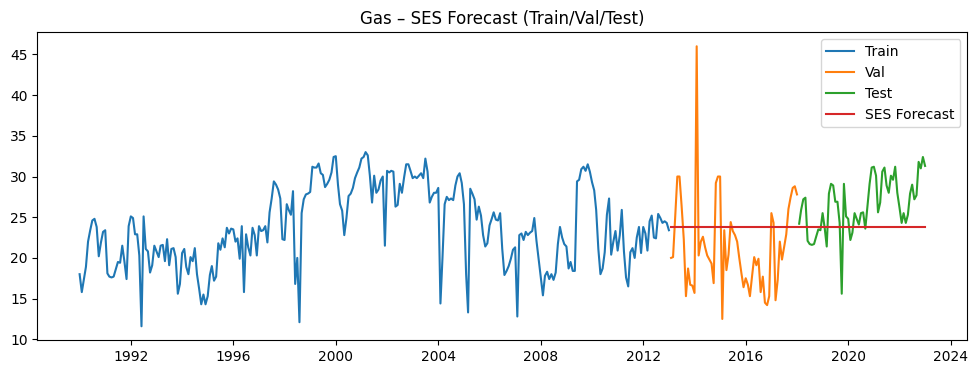

Gas SES Test MAPE: 12.56%
Gas SES Test MAE: 3.45
Gas SES Test RMSE: 4.26


In [39]:
ses_gas = SimpleExpSmoothing(
    train["Gas Consumption (tons)"].astype(float)
).fit()

# forecast validation + test
n_future = len(val) + len(test)
ses_gas_forecast = ses_gas.forecast(n_future)
ses_gas_forecast.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Gas Consumption (tons)"], label="Train")
plt.plot(val.index, val["Gas Consumption (tons)"], label="Val")
plt.plot(test.index, test["Gas Consumption (tons)"], label="Test")
plt.plot(ses_gas_forecast.index, ses_gas_forecast, label="SES Forecast")
plt.title("Gas – SES Forecast (Train/Val/Test)")
plt.legend()
plt.show()

# metrics (test only)
actual_gas = test["Gas Consumption (tons)"].astype(float).values
pred_gas = ses_gas_forecast.loc[test.index].astype(float).values

mape_gas_ses = mean_absolute_percentage_error(actual_gas, pred_gas)
mae_gas_ses  = mean_absolute_error(actual_gas, pred_gas)
rmse_gas_ses = np.sqrt(mean_squared_error(actual_gas, pred_gas))

print(f"Gas SES Test MAPE: {mape_gas_ses*100:.2f}%")
print(f"Gas SES Test MAE: {mae_gas_ses:.2f}")
print(f"Gas SES Test RMSE: {rmse_gas_ses:.2f}")


**Gas – SES (Baseline) – Evaluation**

**Metrics (Test Set):**  
- MAPE: **12.56%** : average error is about **12–13%**.  
- MAE: **3.45** : predictions are off by about **3.5 tons per month** on average.  
- RMSE: **4.26** : slightly higher than MAE, showing occasional larger errors.

**Interpretation:**  
SES produces a nearly flat forecast because it ignores trend and seasonality.  
Gas shows clear seasonal movement, so SES cannot track it well, leading to higher errors.

#### 4.2.2 Gas: Holt‑Winters (Additive)

The gas decomposition shows stable yearly seasonal amplitude, so additive seasonality is appropriate. Holt‑Winters captures both trend and seasonality and should outperform SES.

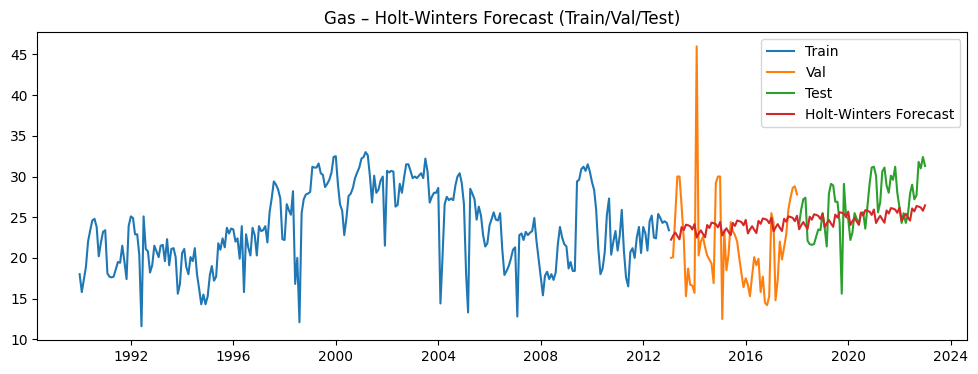

Gas HW Test MAPE: 9.98%
Gas HW Test MAE: 2.64
Gas HW Test RMSE: 3.38


In [80]:
hw_gas = ExponentialSmoothing(
    train["Gas Consumption (tons)"].astype(float),
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

# forecast validation + test
n_future = len(val) + len(test)
hw_gas_forecast = hw_gas.forecast(n_future)
hw_gas_forecast.index = val.index.append(test.index)

# metrics (test only)
actual_gas = test["Gas Consumption (tons)"].astype(float).values
pred_gas = hw_gas_forecast.loc[test.index].astype(float).values

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Gas Consumption (tons)"], label="Train")
plt.plot(val.index, val["Gas Consumption (tons)"], label="Val")
plt.plot(test.index, test["Gas Consumption (tons)"], label="Test")
plt.plot(hw_gas_forecast.index, hw_gas_forecast, label="Holt‑Winters Forecast")
plt.title("Gas – Holt‑Winters Forecast (Train/Val/Test)")
plt.legend()
plt.show()

mape_gas_hw = mean_absolute_percentage_error(actual_gas, pred_gas)
mae_gas_hw  = mean_absolute_error(actual_gas, pred_gas)
rmse_gas_hw = np.sqrt(mean_squared_error(actual_gas, pred_gas))

print(f"Gas HW Test MAPE: {mape_gas_hw*100:.2f}%")
print(f"Gas HW Test MAE: {mae_gas_hw:.2f}")
print(f"Gas HW Test RMSE: {rmse_gas_hw:.2f}")


**Gas – Holt‑Winters (Additive) – Evaluation**

**Metrics (Test Set):**  
- MAPE: **9.98** → average error is about **10%**.  
- MAE: **2.64** → predictions are off by about **2.6 tons per month** on average.  
- RMSE: **3..38** → slightly higher than MAE, showing occasional larger errors.

**Interpretation:**  
Holt‑Winters captures seasonality better than SES, but gas has spikes/outlier that reduce accuracy.  
Because of these irregular fluctuations, improvements over SES are limited.

#### 4.2.3 Gas: SARIMA

SARIMA is used because it captures both seasonal and non‑seasonal dynamics.  
ADF shows the series is stationary (p‑value < 0.05), so no regular differencing is needed, **d = 0**.  
The decomposition shows a strong yearly seasonal cycle, so **D = 1** and **m = 12** are used.  
Small AR/MA terms (**p = 1, q = 1; P = 1, Q = 1**) are chosen as a simple baseline consistent with the decomposition.


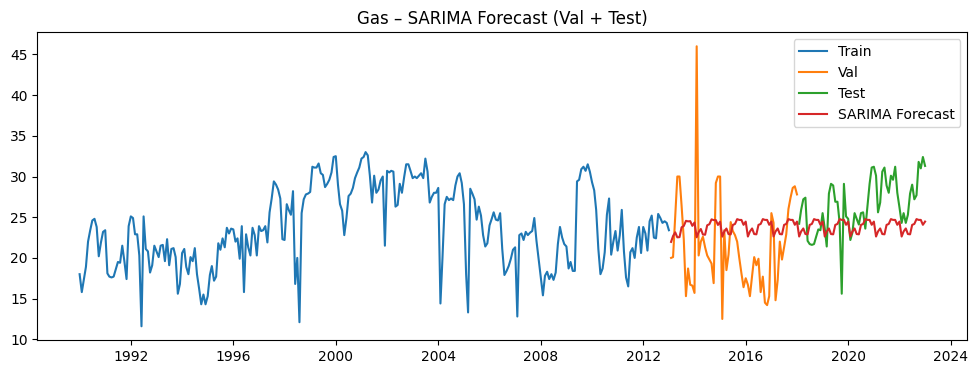

Gas SARIMA Test MAPE: 12.70%
Gas SARIMA Test MAE: 3.45
Gas SARIMA Test RMSE: 4.20


In [145]:
sarima_gas = SARIMAX(
    train["Gas Consumption (tons)"].astype(float),
    order=(1,0,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# forecast validation + test
n_future = len(val) + len(test)
pred_gas = sarima_gas.forecast(steps=n_future)
pred_gas.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Gas Consumption (tons)"], label="Train")
plt.plot(val.index, val["Gas Consumption (tons)"], label="Val")
plt.plot(test.index, test["Gas Consumption (tons)"], label="Test")
plt.plot(pred_gas.index, pred_gas, label="SARIMA Forecast")
plt.title("Gas – SARIMA Forecast (Val + Test)")
plt.legend()
plt.show()

# metrics (test only)
actual_gas = test["Gas Consumption (tons)"].astype(float).values
pred_gas_test = pred_gas.loc[test.index].astype(float).values

mape_gas_sar = mean_absolute_percentage_error(actual_gas, pred_gas_test)
mae_gas_sar  = mean_absolute_error(actual_gas, pred_gas_test)
rmse_gas_sar = np.sqrt(mean_squared_error(actual_gas, pred_gas_test))

print(f"Gas SARIMA Test MAPE: {mape_gas_sar*100:.2f}%")
print(f"Gas SARIMA Test MAE: {mae_gas_sar:.2f}")
print(f"Gas SARIMA Test RMSE: {rmse_gas_sar:.2f}")

**Gas – SARIMA – Evaluation**

**Metrics (Test Set):**  
- MAPE: **12.7%** : average error is about **12–13%**.  
- MAE: **3.45** : predictions are off by about **3.45 tons per month** on average.  
- RMSE: **4.2** : slightly higher than MAE, showing occasional larger errors.

**Interpretation:**  
The initial SARIMA order outperform SES but does not outperform or Holt‑Winters, suggesting the starting parameters might not be well matched to gas dynamics.


#### 4.2.4 Gas: Tuning SARIMA

- m = 12 because the data is monthly and decomposition shows a clear yearly cycle.  
- d, D = [0, 1] to test both stationary and non‑stationary cases (ADF results can vary by series).  
- p, q, P, Q = [0, 1, 2] keeps the search focused on simple AR/MA structures to avoid overfitting while still capturing short‑term and seasonal dynamics.

In [86]:
y_train_gas = train["Gas Consumption (tons)"].astype(float)
y_val_gas   = val["Gas Consumption (tons)"].astype(float)

# Gas tuning ranges
p = q = [0, 1, 2]
P = Q = [0, 1, 2]
d = D = [0,1]
m = [12]

results_gas = []
count_g = 0
total_g = len(p)*len(q)*len(P)*len(Q)*len(d)*len(D)*len(m)

for m_ in m:
    for d_ in d:
        for D_ in D:
            for p_ in p:
                for q_ in q:
                    for P_ in P:
                        for Q_ in Q:
                            count_g += 1
                            order_g = (p_, d_, q_)
                            seasonal_g = (P_, D_, Q_, m_)
                            try:
                                model_g = SARIMAX(
                                    y_train_gas,
                                    order=order_g,
                                    seasonal_order=seasonal_g,
                                    enforce_stationarity=False,
                                    enforce_invertibility=False
                                ).fit(disp=False)

                                pred_val_g = model_g.forecast(steps=len(y_val_gas))
                                mape_val_g = mean_absolute_percentage_error(y_val_gas.values, pred_val_g.values)

                                results_gas.append({
                                    "order": order_g,
                                    "seasonal_order": seasonal_g,
                                    "val_mape": mape_val_g
                                })

                                if count_g % 20 == 0 or count_g == 1 or count_g == total_g:
                                    best_mape_g = min(r["val_mape"] for r in results_gas)
                                    print(f"{count_g}/{total_g} done, best val MAPE so far: {best_mape_g*100:.2f}%")
                            except Exception:
                                pass

results_df_gas = pd.DataFrame(results_gas)

print("\nTop 10 Gas SARIMA by Validation MAPE:")
print(results_df_gas.sort_values("val_mape").head(10))

best_order_g = results_df_gas.sort_values("val_mape").iloc[0]["order"]
best_seasonal_g = results_df_gas.sort_values("val_mape").iloc[0]["seasonal_order"]

print("\nBest Gas SARIMA config by Validation MAPE:")
print("Best order:", best_order_g)
print("Best seasonal_order:", best_seasonal_g)
print(f"Best Validation MAPE: {results_df_gas.sort_values('val_mape').iloc[0]['val_mape']*100:.2f}%")

1/81 done, best val MAPE so far: 23.12%
20/81 done, best val MAPE so far: 21.97%
40/81 done, best val MAPE so far: 21.97%
60/81 done, best val MAPE so far: 21.97%
80/81 done, best val MAPE so far: 21.97%
81/81 done, best val MAPE so far: 21.97%

Top 10 Gas SARIMA by Validation MAPE:
        order seasonal_order  val_mape
6   (0, 1, 0)  (2, 1, 0, 12)  0.219710
33  (1, 1, 0)  (2, 1, 0, 12)  0.219995
60  (2, 1, 0)  (2, 1, 0, 12)  0.220810
15  (0, 1, 1)  (2, 1, 0, 12)  0.220818
2   (0, 1, 0)  (0, 1, 2, 12)  0.225131
7   (0, 1, 0)  (2, 1, 1, 12)  0.226171
24  (0, 1, 2)  (2, 1, 0, 12)  0.227133
42  (1, 1, 1)  (2, 1, 0, 12)  0.230271
51  (1, 1, 2)  (2, 1, 0, 12)  0.230301
69  (2, 1, 1)  (2, 1, 0, 12)  0.230310

Best Gas SARIMA config by Validation MAPE:
Best order: (0, 1, 0)
Best seasonal_order: (2, 1, 0, 12)
Best Validation MAPE: 21.97%


In [104]:
best_model_g = SARIMAX(
    train["Gas Consumption (tons)"].astype(float),
    order=best_order_g,
    seasonal_order=best_seasonal_g,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# Forecast test
pred_test_g = best_model_g.forecast(steps=len(test))

actual_test_g = test["Gas Consumption (tons)"].values
pred_test_g_vals = pred_test_g.values

mape_test_g = mean_absolute_percentage_error(actual_test_g, pred_test_g_vals)
mae_test_g  = mean_absolute_error(actual_test_g, pred_test_g_vals)
rmse_test_g = np.sqrt(mean_squared_error(actual_test_g, pred_test_g_vals))

print(f"Gas SARIMA Test MAPE: {mape_test_g*100:.2f}%")
print(f"Gas SARIMA Test MAE: {mae_test_g:.2f}")
print(f"Gas SARIMA Test RMSE: {rmse_test_g:.2f}")


Gas SARIMA Test MAPE: 20.29%
Gas SARIMA Test MAE: 5.61
Gas SARIMA Test RMSE: 6.56


**Gas – SARIMA (After Tuning) – Evaluation**

**Metrics:**  
- Best Validation MAPE: **21.97%**  
- Test MAPE: **20.29%**  
- Test MAE: **5.61**  
- Test RMSE: **6.56**

**Interpretation:**  
Tuning with MAPE did not improve results. Gas contains strong spikes/outliers in the validation period, and MAPE becomes unstable.  
This leads the tuned model to perform worse on test data.

**Conclusion:**  
For gas, SES/Holt‑Winters are more stable than the tuned SARIMA under current settings.

#### 4.2.5 Gas – Model Improvement

**Seasonality effect:**  
SES (MAPE 12.56%) cannot capture the yearly cycle.  
Adding seasonality with Holt‑Winters improves accuracy (MAPE 9.98%), showing the seasonal component matters for gas.

**Tuning effect (SARIMA):**  
- Before tuning (SARIMA baseline): MAPE 12.71% 
- After tuning (SARIMA tuned): MAPE 20.29%  
Tuning made performance worse, likely because the validation‑optimized parameters overfit irregular spikes that did not generalize to the test period.


#### 4.2.6 Gas: Model Comparison 

- SES (baseline): MAPE **12.56%**  
- Holt‑Winters: MAPE **9.98%**   
- SARIMA (before tuning): MAPE **12.71%**  
- SARIMA (after tuning): MAPE **20.29%**

**Final Choice:**  
**Holt‑Winters** is selected because it gives the **lowest test MAPE** and most stable performance for gas.


### 4.3 Model Evaluation for Water

#### 4.3.1 Water: Baseline Model

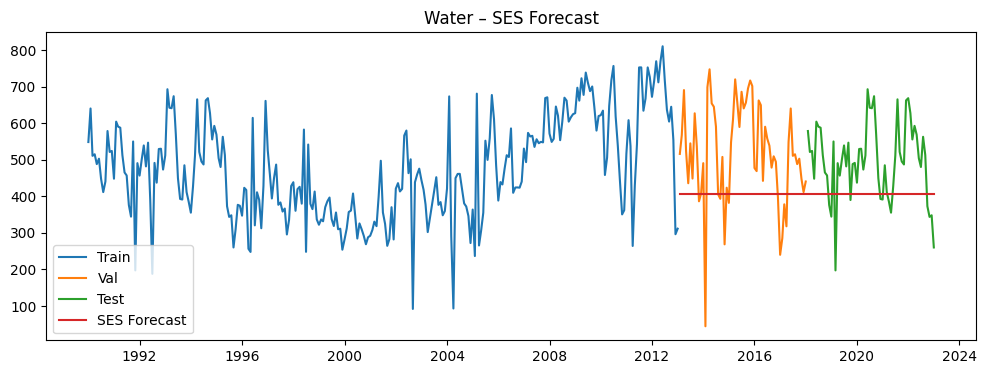

Water SES Test MAPE: 22.70%
Water SES Test MAE: 115.65
Water SES Test RMSE: 137.19


In [86]:
ses_water = SimpleExpSmoothing(
    train["Water Consumption (tons)"].astype(float)
).fit()

# forecast validation + test
n_future = len(val) + len(test)
ses_water_forecast = ses_water.forecast(n_future)
ses_water_forecast.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Water Consumption (tons)"], label="Train")
plt.plot(val.index, val["Water Consumption (tons)"], label="Val")
plt.plot(test.index, test["Water Consumption (tons)"], label="Test")
plt.plot(ses_water_forecast.index, ses_water_forecast, label="SES Forecast")
plt.title("Water – SES Forecast")
plt.legend()
plt.show()

# metrics (test only)
actual_water = test["Water Consumption (tons)"].astype(float).values
pred_water = ses_water_forecast.loc[test.index].astype(float).values

mape_water_ses = mean_absolute_percentage_error(actual_water, pred_water)
mae_water_ses  = mean_absolute_error(actual_water, pred_water)
rmse_water_ses = np.sqrt(mean_squared_error(actual_water, pred_water))

print(f"Water SES Test MAPE: {mape_water_ses*100:.2f}%")
print(f"Water SES Test MAE: {mae_water_ses:.2f}")
print(f"Water SES Test RMSE: {rmse_water_ses:.2f}")

**Water – SES (Baseline) – Evaluation**
 
- MAPE: **22.70%** → average error is about **23%**.  
- MAE: **115.65** → predictions are off by about **116 tons per month** on average.  
- RMSE: **137.19** → higher than MAE, indicating occasional larger errors.

**Interpretation:**  
SES produces a nearly flat forecast and does not capture the trend or strong seasonal pattern in water usage, leading to high error.

**Conclusion:**  
SES is not suitable for water forecasting and serves only as a baseline.


#### 4.3.2 Water: Holt-Winter with seasonality

- The seasonal swings are roughly constant over time, so **additive seasonality** is appropriate (`seasonal="add"`).  
- The trend changes gradually and does not grow proportionally, so **additive trend** fits better (`trend="add"`).  
- The data is monthly and shows a clear yearly cycle, so **seasonal_periods = 12**.


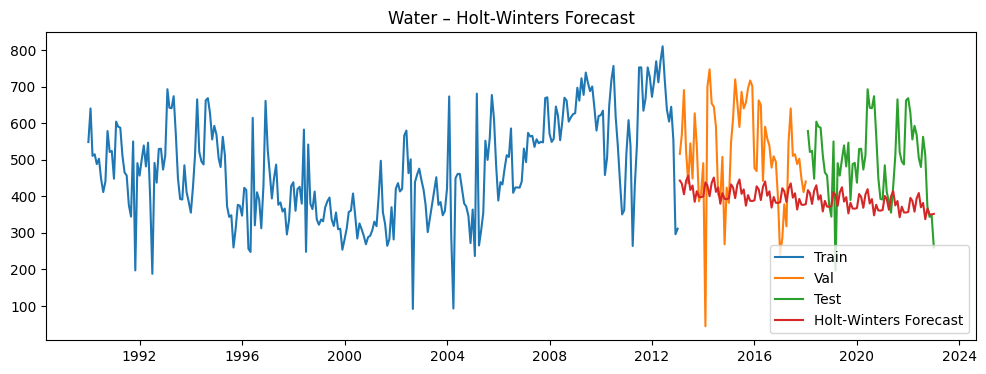

Water HW Test MAPE: 24.77%
Water HW Test MAE: 129.20
Water HW Test RMSE: 154.23


In [146]:
hw_water = ExponentialSmoothing(
    train["Water Consumption (tons)"].astype(float),
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

# forecast validation + test
n_future = len(val) + len(test)
hw_water_forecast = hw_water.forecast(n_future)
hw_water_forecast.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Water Consumption (tons)"], label="Train")
plt.plot(val.index, val["Water Consumption (tons)"], label="Val")
plt.plot(test.index, test["Water Consumption (tons)"], label="Test")
plt.plot(hw_water_forecast.index, hw_water_forecast, label="Holt‑Winters Forecast")
plt.title("Water – Holt‑Winters Forecast")
plt.legend()
plt.show()

# metrics (test only)
actual_water = test["Water Consumption (tons)"].astype(float).values
pred_water = hw_water_forecast.loc[test.index].astype(float).values

mape_water_hw = mean_absolute_percentage_error(actual_water, pred_water)
mae_water_hw  = mean_absolute_error(actual_water, pred_water)
rmse_water_hw = np.sqrt(mean_squared_error(actual_water, pred_water))

print(f"Water HW Test MAPE: {mape_water_hw*100:.2f}%")
print(f"Water HW Test MAE: {mae_water_hw:.2f}")
print(f"Water HW Test RMSE: {rmse_water_hw:.2f}")

**Water – Holt-winter – Evaluation**

**Metrics (Test Set):**  
- MAPE: **24.77%** : average error is about **25%**.  
- MAE: **129.2** : predictions are off by about **129 tons per month** on average.  
- RMSE: **154.23** : higher than MAE, indicating occasional larger errors.

**Interpretation:**  
Holt-winter captures the yearly seasonality, but the remaining variability and spikes in water usage still lead to moderate error.

**Conclusion:**  
Holt-winter provides a reasonable seasonal forecast for water, but accuracy is limited by irregular fluctuations in the series.

#### 4.3.3 Water: SARIMA

**Seasonality:** Decomposition shows a strong yearly cycle **m = 12** and **D = 1**.  
- **Stationarity:** ADF indicates the series is stationary after seasonal differencing **d = 0**.  
- **Complex dynamics:** Water shows a more irregular trend and larger fluctuations, so I used **slightly higher AR terms** (**p = 2**, **P = 2**) to capture longer dependence.  
- **MA terms:** **q = 1** and **Q = 1** keep the model flexible for shocks without being overly complex.


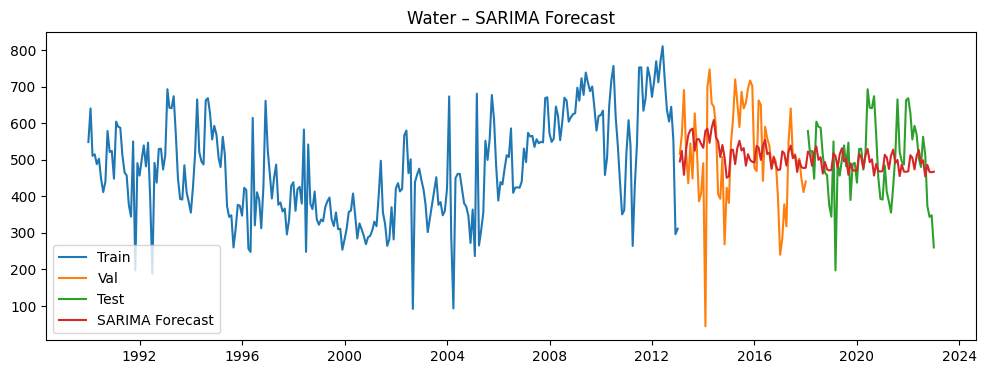

Water SARIMA Test MAPE: 17.87%
Water SARIMA Test MAE: 77.92
Water SARIMA Test RMSE: 100.74


In [109]:
sarima_water = SARIMAX(
    train["Water Consumption (tons)"].astype(float),
    order=(2,0,1),
    seasonal_order=(2,1,1,12)
).fit(disp=False)

# forecast validation + test
n_future = len(val) + len(test)
pred_water = sarima_water.forecast(steps=n_future)
pred_water.index = val.index.append(test.index)

# plot
plt.figure(figsize=(12,4))
plt.plot(train.index, train["Water Consumption (tons)"], label="Train")
plt.plot(val.index, val["Water Consumption (tons)"], label="Val")
plt.plot(test.index, test["Water Consumption (tons)"], label="Test")
plt.plot(pred_water.index, pred_water, label="SARIMA Forecast")
plt.title("Water – SARIMA Forecast")
plt.legend()
plt.show()

# metrics (test only)
actual_water = test["Water Consumption (tons)"].astype(float).values
pred_water_test = pred_water.loc[test.index].astype(float).values

mape_water_sar = mean_absolute_percentage_error(actual_water, pred_water_test)
mae_water_sar  = mean_absolute_error(actual_water, pred_water_test)
rmse_water_sar = np.sqrt(mean_squared_error(actual_water, pred_water_test))

print(f"Water SARIMA Test MAPE: {mape_water_sar*100:.2f}%")
print(f"Water SARIMA Test MAE: {mae_water_sar:.2f}")
print(f"Water SARIMA Test RMSE: {rmse_water_sar:.2f}")



**Water – SARIMA – Evaluation**

**Metrics (Test Set):**  
- MAPE: **17.87%** : average error is about **18%**.  
- MAE: **77.92** : predictions are off by about **78 tons per month** on average.  
- RMSE: **100.74** : higher than MAE, indicating occasional larger errors.

**Interpretation:**  
SARIMA captures the yearly seasonality, but the remaining variability and spikes in water usage still lead to moderate error.

**Conclusion:**  
SARIMA provides a reasonable seasonal forecast for water, but accuracy is limited by irregular fluctuations in the series.

#### 4.3.4 SARIMA Tuning

- **m = 12** because the data is monthly and the decomposition shows a clear yearly cycle.  
- **D = 1** because water shows seasonal pattern.  
- **p, q up to 3** allow moderate short‑term dynamics without overfitting.  
- **P up to 3, Q up to 2** allow some seasonal dynamics while keeping the grid manageable.

In [122]:
y_train_water = train["Water Consumption (tons)"].astype(float)
y_val_water   = val["Water Consumption (tons)"].astype(float)

# Water tuning ranges
p = [0, 1, 2, 3]
P = [1, 2, 3]
Q = [0, 1, 2]
q = [0, 1, 2]
d = [0]
D = [1]
m = [12]

results_water = []
count_w = 0
total_w = len(p)*len(q)*len(P)*len(Q)*len(d)*len(D)*len(m)

for m_ in m:
    for d_ in d:
        for D_ in D:
            for p_ in p:
                for q_ in q:
                    for P_ in P:
                        for Q_ in Q:
                            count_w += 1
                            order_w = (p_, d_, q_)
                            seasonal_w = (P_, D_, Q_, m_)
                            try:
                                model_w = SARIMAX(
                                    y_train_water,
                                    order=order_w,
                                    seasonal_order=seasonal_w,
                                    enforce_stationarity=False,
                                    enforce_invertibility=False
                                ).fit(disp=False)

                                pred_val_w = model_w.forecast(steps=len(y_val_water))
                                mape_val_w = mean_absolute_percentage_error(
                                    y_val_water.values, pred_val_w.values
                                )

                                results_water.append({
                                    "order": order_w,
                                    "seasonal_order": seasonal_w,
                                    "val_mape": mape_val_w
                                })

                                if count_w % 20 == 0 or count_w == 1 or count_w == total_w:
                                    best_mape_w = min(r["val_mape"] for r in results_water)
                                    print(f"{count_w}/{total_w} done, best val MAPE so far: {best_mape_w*100:.2f}%")
                            except Exception:
                                pass

results_df_water = pd.DataFrame(results_water)

print("\nTop 20 Water SARIMA by Validation MAPE:")
print(results_df_water.sort_values("val_mape").head(20))

best_order_w = results_df_water.sort_values("val_mape").iloc[0]["order"]
best_seasonal_w = results_df_water.sort_values("val_mape").iloc[0]["seasonal_order"]

print("\nBest Water SARIMA config by Validation MAPE:")
print("Best order:", best_order_w)
print("Best seasonal_order:", best_seasonal_w)
print(f"Best Validation MAPE: {results_df_water.sort_values('val_mape').iloc[0]['val_mape']*100:.2f}%")


1/108 done, best val MAPE so far: 52.89%
20/108 done, best val MAPE so far: 48.50%
40/108 done, best val MAPE so far: 38.38%
60/108 done, best val MAPE so far: 38.23%
80/108 done, best val MAPE so far: 38.09%
100/108 done, best val MAPE so far: 38.09%
108/108 done, best val MAPE so far: 35.80%

Top 20 Water SARIMA by Validation MAPE:
         order seasonal_order  val_mape
106  (3, 0, 2)  (3, 1, 1, 12)  0.358024
73   (2, 0, 2)  (1, 1, 1, 12)  0.380872
46   (1, 0, 2)  (1, 1, 1, 12)  0.382253
98   (3, 0, 1)  (3, 1, 2, 12)  0.382770
77   (2, 0, 2)  (2, 1, 2, 12)  0.383368
37   (1, 0, 1)  (1, 1, 1, 12)  0.383772
43   (1, 0, 1)  (3, 1, 1, 12)  0.385324
44   (1, 0, 1)  (3, 1, 2, 12)  0.386022
50   (1, 0, 2)  (2, 1, 2, 12)  0.387417
41   (1, 0, 1)  (2, 1, 2, 12)  0.388347
95   (3, 0, 1)  (2, 1, 2, 12)  0.390241
53   (1, 0, 2)  (3, 1, 2, 12)  0.392597
52   (1, 0, 2)  (3, 1, 1, 12)  0.392794
64   (2, 0, 1)  (1, 1, 1, 12)  0.393245
49   (1, 0, 2)  (2, 1, 1, 12)  0.393836
68   (2, 0, 1)  (2, 1, 2

In [127]:
best_model_w = SARIMAX(
    train["Water Consumption (tons)"].astype(float),
    order=(3, 0, 2),
    seasonal_order=(3, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

pred_test_w = best_model_w.forecast(steps=len(test))

actual_w = test["Water Consumption (tons)"].values
pred_w = pred_test_w.values

mape = mean_absolute_percentage_error(actual_w, pred_w)
mae  = mean_absolute_error(actual_w, pred_w)
rmse = np.sqrt(mean_squared_error(actual_w, pred_w))

print(f"Water SARIMA Test MAPE: {mape*100:.2f}%")
print(f"Water SARIMA Test MAE: {mae:.2f}")
print(f"Water SARIMA Test RMSE: {rmse:.2f}")

Water SARIMA Test MAPE: 19.97%
Water SARIMA Test MAE: 91.15
Water SARIMA Test RMSE: 111.65


**Water – SARIMA (Tuned) – Evaluation**

- MAPE: **19.97%** : average error is about **20%**.  
- MAE: **91.15** : predictions are off by about **91 tons per month** on average.  
- RMSE: **111.65** : higher than MAE, indicating occasional larger errors.

**Interpretation:**  
The tuned SARIMA captures yearly seasonality, but the water series has irregular spikes and structural changes that are hard to model.  
Tuning on validation may have selected parameters that fit those spikes, which **did not generalize** well to the test period.  
This is why the tuned model performs worse than the initial SARIMA despite a more thorough search.

**Conclusion:**  
Tuned SARIMA is still a reasonable seasonal model, but its accuracy is limited by volatility and outlier behavior in the water series.


#### 4.3.5 Water – Model Improvement

**Seasonality effect:**  
SES (MAPE 22.70%) performs poorly because it ignores strong seasonal patterns.  
Baseline SARIMA captures seasonality and improves accuracy (MAPE 17.87%).

**Tuning effect (SARIMA):**  
- Before tuning (SARIMA baseline): MAPE 17.87% 
- After tuning (SARIMA tuned): MAPE 19.97% 
Tuning did not improve results; the tuned model likely fit validation‑period volatility that did not carry into the test data.


#### 4.3.6 Water: Model Comparison 
- SES (baseline): MAPE **22.70%**  
- Holt‑Winters (Additive): MAPE **24.77%** 
- SARIMA : MAPE **17.87%**  
- SARIMA (tuned): MAPE **19.97%**
- 
**Final Choice:**  
**SARIMA (untuned)** is selected because it has the **lowest error across all metrics**.


## 5. Model Prediction

### 5.1 Sixty Month Prediction for Electricity with Best Model

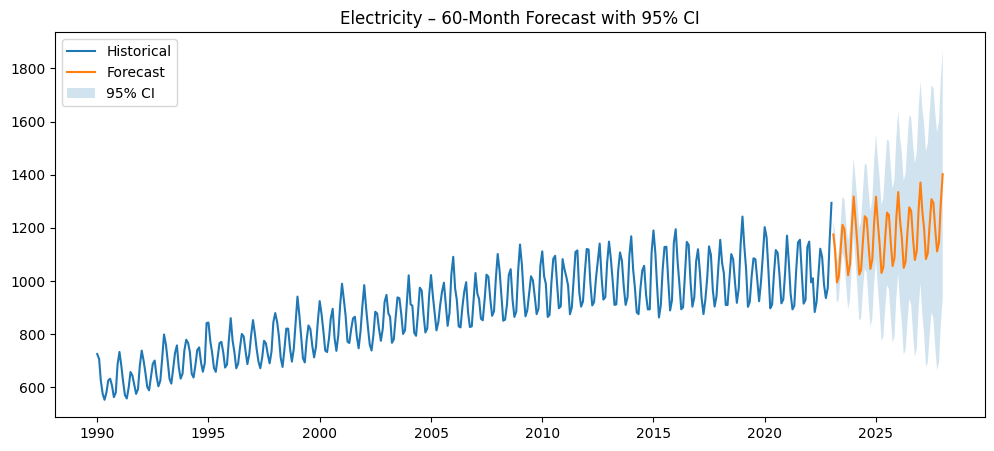

In [114]:
elec_full = df["Electricity Consumption (MWh)"].astype(float)

final_sarima_elec = SARIMAX(
    elec_full,
    order=(1, 1, 0),
    seasonal_order=(3, 1, 1, 12)
).fit(disp=False)

fc_elec = final_sarima_elec.get_forecast(steps=60)
fc_mean = fc_elec.predicted_mean
fc_ci = fc_elec.conf_int(alpha=0.05)

plt.figure(figsize=(12,5))
plt.plot(elec_full.index, elec_full, label="Historical")
plt.plot(fc_mean.index, fc_mean, label="Forecast")
plt.fill_between(fc_ci.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], alpha=0.2, label="95% CI")
plt.title("Electricity – 60‑Month Forecast with 95% CI")
plt.legend()
plt.show()

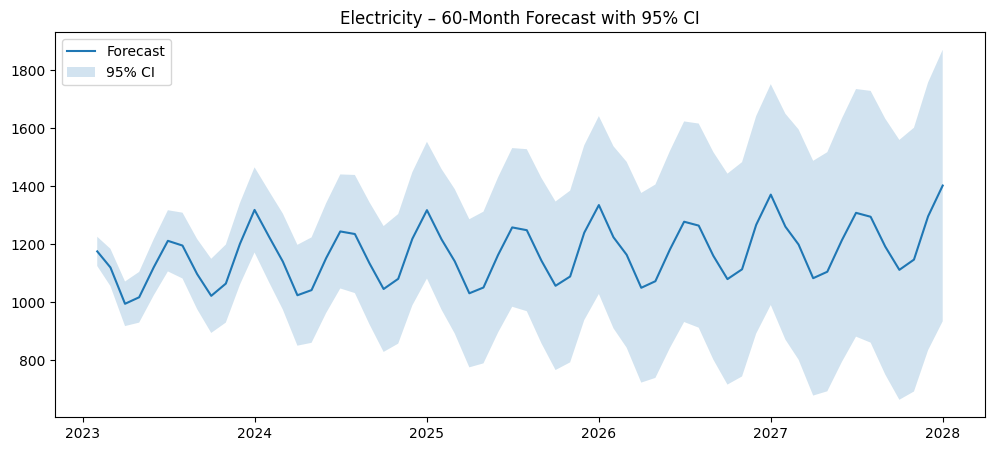

{'mean_start': np.float64(1175.0009231579581),
 'mean_end': np.float64(1401.9451340941698),
 'mean_min': 994.3553563912386,
 'mean_max': 1401.9451340941698,
 'ci_lower_min': 663.4192554515032,
 'ci_upper_max': 1870.0286071105497,
 'avg_ci_width': np.float64(543.0761530546372)}

In [133]:
plt.figure(figsize=(12,5))
plt.plot(fc_mean.index, fc_mean, label="Forecast")
plt.fill_between(fc_ci.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], alpha=0.2, label="95% CI")
plt.title("Electricity – 60‑Month Forecast with 95% CI")
plt.legend()
plt.show()
summary = {
    "mean_start": fc_mean.iloc[0],
    "mean_end": fc_mean.iloc[-1],
    "mean_min": fc_mean.min(),
    "mean_max": fc_mean.max(),
    "ci_lower_min": fc_ci.iloc[:,0].min(),
    "ci_upper_max": fc_ci.iloc[:,1].max(),
    "avg_ci_width": (fc_ci.iloc[:,1] - fc_ci.iloc[:,0]).mean()
}
summary

**Electricity Forecast – Numerical Summary (Approx.)**

- Forecast mean starts around **1,175** and rises to about **1,400** by the end.  
- Mean forecast range is roughly **1,000 to 1,400**.  
- 95% CI spans roughly **660 (lower)** to **1,870 (upper)** at its widest.  
- Average uncertainty band is about **540** units wide.

#### Trend Reflection for Electricity

- The historical series shows a **consistent upward shift in level** across the full timeline, so the model assumes this gradual growth continues into the forecast horizon rather than reversing.  
- The decomposition and fitted SARIMA both show a **stable yearly seasonal cycle**, so the forecast repeats the same annual pattern (peaks and troughs at similar times each year).  
- The SARIMA framework assumes **future dynamics are similar to past dynamics** (no sudden structural break in policy, economy, or usage behavior), so it extrapolates the observed trend and seasonality forward.  
- The **widening confidence interval** reflects accumulating uncertainty: as the forecast extends further from known data, the range of plausible outcomes expands even if the mean trend remains upward.  
- Overall, the forecast is driven by the **long‑run growth signal** in the data, while uncertainty bands acknowledge that unexpected shocks could push actual values above or below the projected path.


### 5.2 Sixty Month Prediction for Gas with Best Model

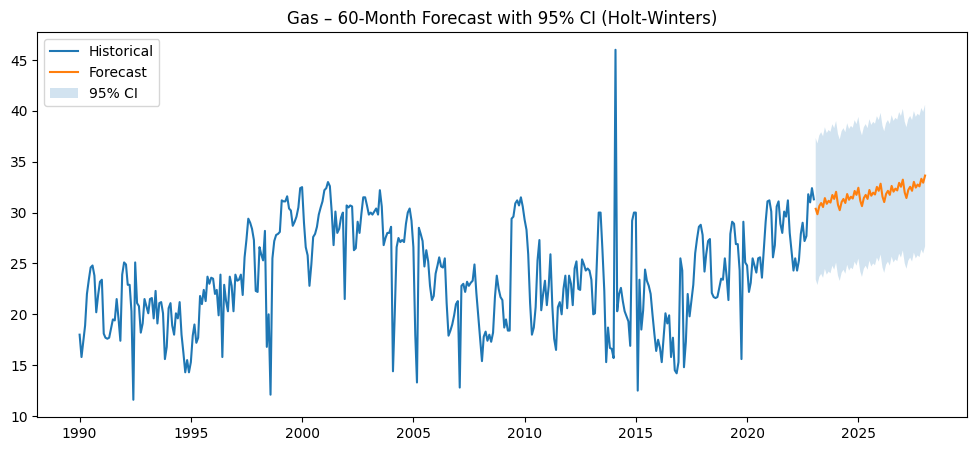

In [105]:
gas_full = df["Gas Consumption (tons)"].astype(float)

# fit final Holt‑Winters
final_hw_gas = ExponentialSmoothing(
    gas_full,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit(optimized=True)

# 60‑month forecast
forecast_gas_60 = final_hw_gas.forecast(steps=60)

# residual-based 95% CI
resid_gas = gas_full - final_hw_gas.fittedvalues
sigma_gas = resid_gas.std()
z = 1.96  # 95%

lower_gas = forecast_gas_60 - z * sigma_gas
upper_gas = forecast_gas_60 + z * sigma_gas

# plot
plt.figure(figsize=(12,5))
plt.plot(gas_full.index, gas_full, label="Historical")
plt.plot(forecast_gas_60.index, forecast_gas_60, label="Forecast")
plt.fill_between(forecast_gas_60.index, lower_gas, upper_gas, alpha=0.2, label="95% CI")
plt.title("Gas – 60‑Month Forecast with 95% CI (Holt‑Winters)")
plt.legend()
plt.show()


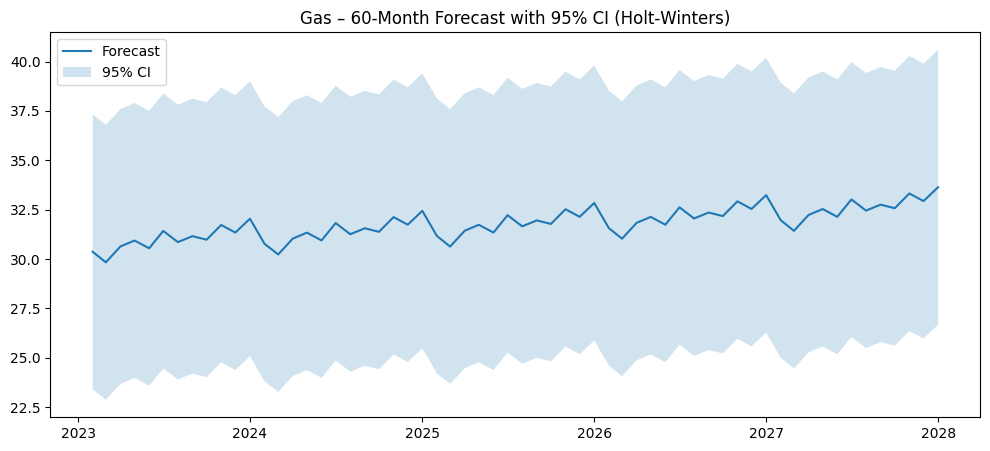

{'mean_start': np.float64(30.372169015690027),
 'mean_end': np.float64(33.63599426073598),
 'mean_min': 29.83567531437296,
 'mean_max': 33.63599426073598,
 'ci_lower_min': 22.877916072630285,
 'ci_upper_max': 40.59375350247865,
 'avg_ci_width': np.float64(13.915518483485346)}

In [134]:
plt.figure(figsize=(12,5))
plt.plot(forecast_gas_60.index, forecast_gas_60, label="Forecast")
plt.fill_between(forecast_gas_60.index, lower_gas, upper_gas, alpha=0.2, label="95% CI")
plt.title("Gas – 60‑Month Forecast with 95% CI (Holt‑Winters)")
plt.legend()
plt.show()
summary_gas = {
    "mean_start": forecast_gas_60.iloc[0],
    "mean_end": forecast_gas_60.iloc[-1],
    "mean_min": forecast_gas_60.min(),
    "mean_max": forecast_gas_60.max(),
    "ci_lower_min": lower_gas.min(),
    "ci_upper_max": upper_gas.max(),
    "avg_ci_width": (upper_gas - lower_gas).mean()
}
summary_gas

**Gas Forecast – Numerical Summary (Approx.)**

- Forecast mean starts around **30.4** and rises to about **33.6** by the end.  
- Mean forecast range is roughly **29.8 to 33.6**.  
- 95% CI spans roughly **22.9 (lower)** to **40.6 (upper)** at its widest.  
- Average uncertainty band is about **13.9** units wide.


**Trend Reflection for Gas**

- The gas forecast shows a **gradual upward trend** from the recent historical levels, with the mean forecast rising slowly over the next 60 months. The growth is modest, indicating steady but not rapid increases in gas consumption.

- The **confidence interval remains relatively stable** across the forecast horizon rather than widening dramatically. This suggests the model expects similar variability in the future and is fairly consistent about the range of likely values throughout the period.

- The Holt‑Winters model assumes **no major structural break**, so past behavior is extended forward.

- The **variation looks larger** because gas has irregular spikes in the historical data, and the model carries that level of variability into the forecast rather than smoothing it out.

- The confidence band does not become wider because Holt‑Winters assumes **constant error variance** over time (it does not model increasing uncertainty with horizon).  
 

- Overall, the model indicates **mild long‑term growth** with a fairly steady uncertainty band, so the forecast range stays consistent while the mean trend increases slowly.

### 5.2 Sixty Month Prediction for Water with Best Model

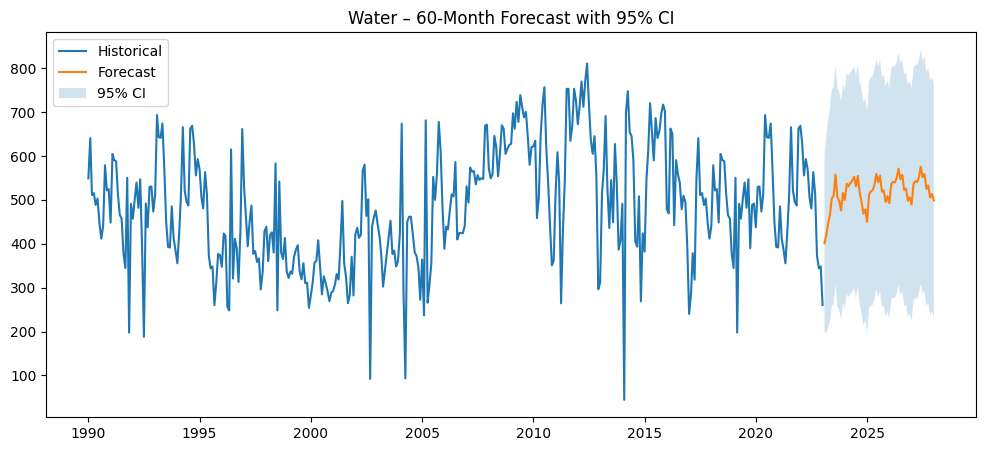

In [128]:
water_full = df["Water Consumption (tons)"].astype(float)

final_sarima_water = SARIMAX(
    water_full,
    order=(2, 1, 1),
    seasonal_order=(2, 1, 1, 12),
).fit(disp=False)

fc_water = final_sarima_water.get_forecast(steps=60)
fc_mean_w = fc_water.predicted_mean
fc_ci_w = fc_water.conf_int(alpha=0.05)

plt.figure(figsize=(12,5))
plt.plot(water_full.index, water_full, label="Historical")
plt.plot(fc_mean_w.index, fc_mean_w, label="Forecast")
plt.fill_between(fc_ci_w.index, fc_ci_w.iloc[:, 0], fc_ci_w.iloc[:, 1], alpha=0.2, label="95% CI")
plt.title("Water – 60‑Month Forecast with 95% CI")
plt.legend()
plt.show()


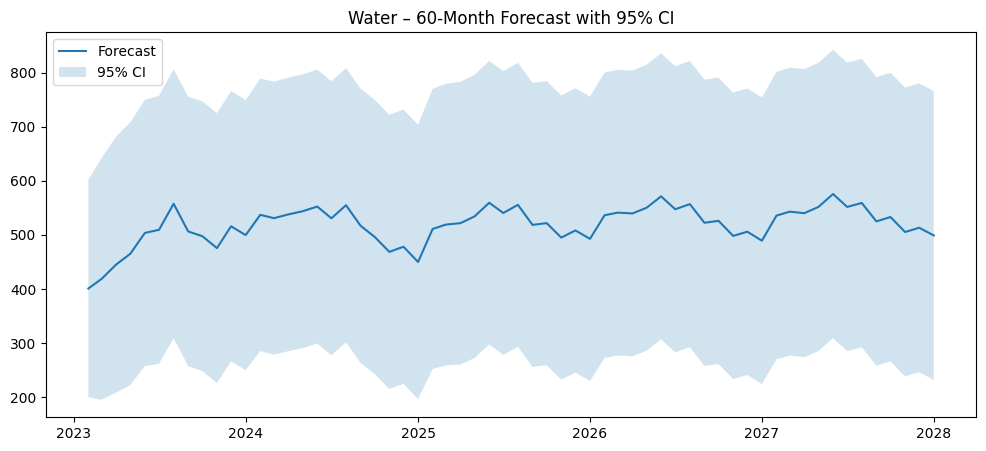

{'mean_start': np.float64(400.94242368831607),
 'mean_end': np.float64(498.941730255432),
 'mean_min': 400.94242368831607,
 'mean_max': 575.6510011186182,
 'ci_lower_min': 195.28312484021114,
 'ci_upper_max': 842.2084093490924,
 'avg_ci_width': np.float64(514.8796194848262)}

In [135]:
plt.figure(figsize=(12,5))
plt.plot(fc_mean_w.index, fc_mean_w, label="Forecast")
plt.fill_between(fc_ci_w.index, fc_ci_w.iloc[:, 0], fc_ci_w.iloc[:, 1], alpha=0.2, label="95% CI")
plt.title("Water – 60‑Month Forecast with 95% CI")
plt.legend()
plt.show()
summary_water = {
    "mean_start": fc_mean_w.iloc[0],
    "mean_end": fc_mean_w.iloc[-1],
    "mean_min": fc_mean_w.min(),
    "mean_max": fc_mean_w.max(),
    "ci_lower_min": fc_ci_w.iloc[:, 0].min(),
    "ci_upper_max": fc_ci_w.iloc[:, 1].max(),
    "avg_ci_width": (fc_ci_w.iloc[:, 1] - fc_ci_w.iloc[:, 0]).mean()
}
summary_water

**Water Forecast – Numerical Summary (Approx.)**

- Forecast mean starts around **401** and rises to about **499** by the end.  
- Mean forecast range is roughly **401 to 576**.  
- 95% CI spans roughly **195 (lower)** to **842 (upper)** at its widest.  
- Average uncertainty band is about **515** units wide.

**Trend Reflection for Water**

- The water forecast shows **moderate stabilization** around the recent level, with the mean forecast oscillating within a fairly narrow band rather than trending strongly up or down. This suggests the model expects water consumption to remain broadly stable, with seasonal ups and downs continuing.

- The **confidence interval is wide and fairly steady** across the forecast horizon. It does not expand sharply, but it stays broad, reflecting the high volatility seen in the historical series. This indicates persistent uncertainty rather than increasing uncertainty over time.

- The SARIMA setup assumes **no major structural break**, so past stability is carried forward into the forecast.  
- The **variance stays roughly constant** because the model assumes **constant error variance** over time; it does not explicitly model increasing volatility.  
- The **wide but steady confidence band** reflects the high historical variability in water usage, which persists into the forecast without expanding further.

- Overall, the model projects **stable consumption with strong variability**, and the wide confidence band highlights that future water usage could fluctuate substantially around the mean forecast.


## 6. Final Conclusion

**Electricity:**  
The series shows a strong upward trend with clear yearly seasonality.  
The final SARIMA model produced the lowest errors and was used for the 60‑month forecast. The forecast continues the upward trend, while uncertainty widens over time.

**Gas:**  
Gas consumption shows modest long‑term growth with seasonal variation.  
Tuned Holt‑Winters performed best among the tested models, indicating that additive trend + seasonality captures gas dynamics effectively. The forecast shows mild growth with relatively stable uncertainty.

**Water:**  
Water consumption is more volatile with a weaker long‑term trend.  
SARIMA provided the best overall performance compared with SES and Holt‑Winters. The 60‑month forecast is relatively flat, and the wide confidence band reflects persistent variability.

**Overall:**  
Seasonal patterns are consistent across all three series, but **trend strength and volatility differ**.  
Forecast uncertainty increases with horizon, so long‑range projections should be treated as approximate ranges rather than exact values.

---
---